# Predicción de cancelaciones de reservas hoteleras
## Notebook 02 · Entrenamiento y evaluación de los modelos (Sección IV)

**Modelos y Simulación de Sistemas II – Universidad de Antioquia**
Juan Camilo Morales Villada · Juan Sebastián Andraus López · Jose Miguel Fajardo Fernández

Este notebook reproduce la Sección IV del informe: la configuración experimental, la búsqueda de hiperparámetros
de seis modelos y sus resultados en entrenamiento, validación y prueba. Usa la limpieza y la codificación definidas
en el notebook 01 (`src/preprocesamiento.py`).

**Tiempo de ejecución aproximado:** 30 a 60 minutos en Google Colab (CPU).

## 1. Configuración

In [1]:
# Solo en Google Colab: descarga el repositorio y se ubica en la carpeta notebooks/
import os, subprocess, sys
REPO = "https://github.com/Moraa0711/ModelosII-Proyecto-HotelBooking.git"
if "google.colab" in sys.modules:
    destino = "/content/ModelosII-Proyecto-HotelBooking"
    if not os.path.exists(destino):
        subprocess.run(["git", "clone", "-q", REPO, destino], check=True)
    os.chdir(os.path.join(destino, "notebooks"))

In [2]:
import json
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import xgboost
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix, roc_curve
from xgboost import XGBClassifier

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(RAIZ))
from src import preprocesamiento as pp
from src import evaluacion as ev

RUTA_FIGURAS = RAIZ / "figuras"; RUTA_FIGURAS.mkdir(exist_ok=True)
RUTA_RESULTADOS = RAIZ / "resultados"; RUTA_RESULTADOS.mkdir(exist_ok=True)
SEMILLA = ev.SEMILLA
warnings.filterwarnings("ignore", category=UserWarning)
plt.rcParams.update({"font.family": "serif", "font.size": 8, "axes.spines.top": False,
                     "axes.spines.right": False})
print("scikit-learn", sklearn.__version__, "| xgboost", xgboost.__version__)

scikit-learn 1.9.1 | xgboost 3.4.1


In [3]:
datos, _ = pp.limpiar_datos(pp.cargar_datos(RAIZ / "data" / "hotel_booking.csv"))
X, y = pp.separar_xy(datos)
grupos = pp.grupos_repetidos(datos)
print(f"Reservas: {len(y):,} | variables de entrada: {X.shape[1]} | canceladas: {y.mean()*100:.2f} %")

Reservas: 119,203 | variables de entrada: 28 | canceladas: 37.07 %


## 2. Configuración experimental (Sección IV-A)

### 2.1 Partición en entrenamiento y prueba
Se separa el 20 % de las reservas como conjunto de **prueba**, que solo se usa una vez al final. La partición es
**estratificada** (conserva el 37 % de canceladas) y **agrupada**: las filas idénticas (reservas de grupo) quedan
completas en un solo lado, para que el modelo no se evalúe con copias exactas de reservas que ya vio.

In [4]:
idx_ent, idx_pru = ev.particion_prueba(X, y, grupos)
X_ent, y_ent, g_ent = X.iloc[idx_ent], y[idx_ent], grupos[idx_ent]
X_pru, y_pru = X.iloc[idx_pru], y[idx_pru]

pd.DataFrame({
    "reservas": [len(y_ent), len(y_pru)],
    "porcentaje": [len(y_ent) / len(y) * 100, len(y_pru) / len(y) * 100],
    "canceladas_%": [y_ent.mean() * 100, y_pru.mean() * 100],
}, index=["Entrenamiento", "Prueba"]).round(2)

,reservas,porcentaje,canceladas_%
Entrenamiento,95363,80.0,37.07
Prueba,23840,20.0,37.08


In [5]:
print("Grupos de filas idénticas presentes en ambos conjuntos:", len(set(g_ent) & set(grupos[idx_pru])))

Grupos de filas idénticas presentes en ambos conjuntos: 0


### 2.2 Validación cruzada
Dentro del conjunto de entrenamiento, los hiperparámetros se escogen con **validación cruzada de 5 particiones,
estratificada y agrupada** (`StratifiedGroupKFold`). Cada combinación se entrena 5 veces; el resultado se reporta como
la media de los 5 pliegues con su **intervalo de confianza del 95 %** (t de Student con 4 grados de libertad), tanto en
entrenamiento como en validación. La codificación y la estandarización se ajustan dentro de cada pliegue (`Pipeline`),
solo con los datos de entrenamiento de ese pliegue.

### 2.3 Desbalance de clases
No se usa sobremuestreo ni submuestreo. En los modelos que lo permiten se asigna un **peso mayor a la clase
minoritaria** (`class_weight="balanced"` en regresión logística, Random Forest y SVM; `scale_pos_weight` en XGBoost).
KNN y la red neuronal de scikit-learn no admiten pesos por clase y se entrenan sin ellos; el desbalance es moderado
(37 % / 63 %).

### 2.4 Muestra para KNN y SVM
El costo de KNN (predicción) y de la SVM con kernel RBF (entrenamiento) crece aproximadamente con el cuadrado del número
de muestras. Por eso estos dos modelos se ajustan con una **muestra estratificada y agrupada de unas 15.000 reservas**
del conjunto de entrenamiento. Todos los modelos se evalúan con el **mismo conjunto de prueba completo**.

In [6]:
idx_muestra = ev.muestra_agrupada(y_ent, g_ent, n=15000)
print(f"Muestra para KNN y SVM: {len(idx_muestra):,} reservas | canceladas: {y_ent[idx_muestra].mean()*100:.2f} %")

Muestra para KNN y SVM: 15,894 reservas | canceladas: 37.08 %


### 2.5 Métricas
- **F1 de la clase cancelada (métrica principal)**: combina precisión y sensibilidad. Es la métrica con la que se escoge
  la mejor combinación de hiperparámetros, porque la exactitud se deja engañar por el desbalance (un clasificador que
  siempre predice "no cancelada" ya obtiene 63 % de exactitud y F1 = 0).
- **AUC-ROC**: capacidad de separar las clases sin depender de un umbral; permite comparar con los artículos revisados.
- **Sensibilidad y precisión**: para un hotel, la sensibilidad indica qué parte de las cancelaciones se detecta y la
  precisión qué tan confiables son las alertas.
- **Exactitud**: se reporta como referencia.

### 2.6 Modelos y mallas de hiperparámetros (Tabla III del informe)

In [7]:
neg, pos = np.bincount(y_ent)
modelos = {
    "Regresión logística": {
        "archivo": "regresion_logistica",
        "tipo": "Paramétrico (regresión)",
        "estimador": LogisticRegression(max_iter=3000, class_weight="balanced"),
        "malla": {"clf__C": [0.001, 0.01, 0.1, 1, 10, 100]},
        "muestra": False, "n_jobs": -1,
    },
    "KNN": {
        "archivo": "knn",
        "tipo": "No paramétrico",
        "estimador": KNeighborsClassifier(),
        "malla": {"clf__n_neighbors": [1, 5, 11, 21, 41, 81], "clf__weights": ["uniform", "distance"]},
        "muestra": True, "n_jobs": -1,
    },
    "Random Forest": {
        "archivo": "random_forest",
        "tipo": "Ensamble de árboles (bagging)",
        "estimador": RandomForestClassifier(n_estimators=200, max_features="sqrt", class_weight="balanced",
                                            n_jobs=-1, random_state=SEMILLA),
        "malla": {"clf__max_depth": [5, 10, 20, None], "clf__min_samples_leaf": [1, 5]},
        "muestra": False, "n_jobs": 1,
    },
    "XGBoost": {
        "archivo": "xgboost",
        "tipo": "Ensamble de árboles (boosting)",
        "estimador": XGBClassifier(n_estimators=400, tree_method="hist", scale_pos_weight=neg / pos,
                                   eval_metric="logloss", n_jobs=-1, random_state=SEMILLA),
        "malla": {"clf__max_depth": [3, 6, 9], "clf__learning_rate": [0.03, 0.1, 0.3]},
        "muestra": False, "n_jobs": 1,
    },
    "Red neuronal (MLP)": {
        "archivo": "mlp",
        "tipo": "Red neuronal artificial",
        "estimador": MLPClassifier(early_stopping=True, max_iter=300, random_state=SEMILLA),
        "malla": {"clf__hidden_layer_sizes": [(32,), (64,), (128, 64)], "clf__alpha": [0.0001, 0.01, 1.0]},
        "muestra": False, "n_jobs": -1,
    },
    "SVM (RBF)": {
        "archivo": "svm",
        "tipo": "Máquina de vectores de soporte",
        "estimador": SVC(kernel="rbf", class_weight="balanced"),
        "malla": {"clf__C": [0.1, 1, 10], "clf__gamma": [0.003, 0.03, 0.3]},
        "muestra": True, "n_jobs": -1,
    },
}

def texto_malla(malla):
    return "; ".join(f"{k.replace('clf__', '')} ∈ {{{', '.join(str(v) for v in vals)}}}" for k, vals in malla.items())

tabla_hp = pd.DataFrame([{
    "Modelo": nombre, "Tipo": m["tipo"], "Hiperparámetros y malla": texto_malla(m["malla"]),
    "Combinaciones": int(np.prod([len(v) for v in m["malla"].values()])),
    "Datos de ajuste": "Muestra (15.000)" if m["muestra"] else "Entrenamiento completo",
} for nombre, m in modelos.items()])
tabla_hp.to_csv(RUTA_RESULTADOS / "tabla_hiperparametros.csv", index=False)
tabla_hp

,Modelo,Tipo,Hiperparámetros y malla,Combinaciones,Datos de ajuste
0,Regresión logística,Paramétrico (regresión),"C ∈ {0.001, 0.01, 0.1, 1, 10, 100}",6,Entrenamiento completo
1,KNN,No paramétrico,"n_neighbors ∈ {1, 5, 11, 21, 41, 81}; weights ...",12,Muestra (15.000)
2,Random Forest,Ensamble de árboles (bagging),"max_depth ∈ {5, 10, 20, None}; min_samples_lea...",8,Entrenamiento completo
3,XGBoost,Ensamble de árboles (boosting),"max_depth ∈ {3, 6, 9}; learning_rate ∈ {0.03, ...",9,Entrenamiento completo
4,Red neuronal (MLP),Red neuronal artificial,"hidden_layer_sizes ∈ {(32,), (64,), (128, 64)}...",9,Entrenamiento completo
5,SVM (RBF),Máquina de vectores de soporte,"C ∈ {0.1, 1, 10}; gamma ∈ {0.003, 0.03, 0.3}",9,Muestra (15.000)


## 3. Resultados (Sección IV-B)

### 3.1 Búsqueda de hiperparámetros
Para cada modelo se prueban todas las combinaciones de la malla con la validación cruzada descrita. Se guardan las
métricas de entrenamiento y validación de cada combinación.

In [8]:
busquedas, tablas = {}, {}
for nombre, m in modelos.items():
    inicio = time.time()
    Xm, ym, gm = (X_ent.iloc[idx_muestra], y_ent[idx_muestra], g_ent[idx_muestra]) if m["muestra"] else (X_ent, y_ent, g_ent)
    pipeline = Pipeline([("prep", pp.construir_preprocesador()), ("clf", m["estimador"])])
    busqueda = GridSearchCV(pipeline, m["malla"], scoring=ev.METRICAS, refit=ev.METRICA_PRINCIPAL,
                            cv=ev.validacion_cruzada(), return_train_score=True, n_jobs=m["n_jobs"])
    busqueda.fit(Xm, ym, groups=gm)
    busquedas[nombre] = busqueda
    parametros = list(m["malla"].keys())
    tablas[nombre] = ev.tabla_busqueda(busqueda, parametros)
    tablas[nombre].to_csv(RUTA_RESULTADOS / f"busqueda_{m['archivo']}.csv", index=False)
    mejor = tablas[nombre].iloc[0]
    print(f"{nombre:22s} {time.time()-inicio:6.0f} s | mejor F1 val {ev.fmt(mejor['f1_val'], mejor['f1_val_ic'])} "
          f"| {busqueda.best_params_}")

Regresión logística        24 s | mejor F1 val 0,742 ± 0,014 | {'clf__C': 10}


KNN                        68 s | mejor F1 val 0,683 ± 0,037 | {'clf__n_neighbors': 41, 'clf__weights': 'distance'}


Random Forest             294 s | mejor F1 val 0,809 ± 0,012 | {'clf__max_depth': None, 'clf__min_samples_leaf': 1}


XGBoost                   176 s | mejor F1 val 0,811 ± 0,011 | {'clf__learning_rate': 0.1, 'clf__max_depth': 9}


Red neuronal (MLP)        232 s | mejor F1 val 0,789 ± 0,010 | {'clf__alpha': 0.0001, 'clf__hidden_layer_sizes': (32,)}


SVM (RBF)                 544 s | mejor F1 val 0,765 ± 0,017 | {'clf__C': 1, 'clf__gamma': 0.03}


### 3.2 Resultados por combinación de hiperparámetros

In [9]:
def mostrar(nombre, n=None):
    t = tablas[nombre].copy()
    cols = [c for c in t.columns if c.startswith("clf__")]
    salida = t[cols].rename(columns=lambda c: c.replace("clf__", ""))
    for m in ["f1", "roc_auc"]:
        salida[f"{ev.NOMBRES_METRICAS[m]} entren."] = [ev.fmt(a, b) for a, b in zip(t[f"{m}_ent"], t[f"{m}_ent_ic"])]
        salida[f"{ev.NOMBRES_METRICAS[m]} valid."] = [ev.fmt(a, b) for a, b in zip(t[f"{m}_val"], t[f"{m}_val_ic"])]
    salida["Ajuste (s)"] = t["tiempo_ajuste_s"].round(1)
    return salida.head(n) if n else salida

for nombre in modelos:
    print(f"\n=== {nombre} ===")
    display(mostrar(nombre))


=== Regresión logística ===


,C,F1 entren.,F1 valid.,AUC-ROC entren.,AUC-ROC valid.,Ajuste (s)
0,10,"0,745 ± 0,003","0,742 ± 0,014","0,891 ± 0,002","0,889 ± 0,007",1.0
1,100,"0,745 ± 0,003","0,742 ± 0,014","0,891 ± 0,002","0,889 ± 0,007",1.1
2,0.1,"0,745 ± 0,003","0,742 ± 0,013","0,891 ± 0,002","0,889 ± 0,007",0.6
3,1,"0,745 ± 0,003","0,742 ± 0,014","0,891 ± 0,002","0,889 ± 0,007",0.8
4,0.01,"0,743 ± 0,003","0,740 ± 0,013","0,889 ± 0,002","0,888 ± 0,007",0.5
5,0.001,"0,738 ± 0,003","0,738 ± 0,013","0,882 ± 0,002","0,881 ± 0,008",0.4



=== KNN ===


,n_neighbors,weights,F1 entren.,F1 valid.,AUC-ROC entren.,AUC-ROC valid.,Ajuste (s)
0,41,distance,"0,993 ± 0,001","0,683 ± 0,037","1,000 ± 0,000","0,852 ± 0,022",0.0
1,5,distance,"0,991 ± 0,001","0,683 ± 0,026","0,997 ± 0,000","0,827 ± 0,023",0.0
2,5,uniform,"0,829 ± 0,002","0,681 ± 0,025","0,947 ± 0,001","0,824 ± 0,024",0.0
3,21,distance,"0,993 ± 0,001","0,679 ± 0,050","1,000 ± 0,000","0,847 ± 0,026",0.0
4,11,distance,"0,992 ± 0,001","0,676 ± 0,043","1,000 ± 0,000","0,843 ± 0,027",0.0
5,41,uniform,"0,731 ± 0,006","0,674 ± 0,032","0,896 ± 0,003","0,847 ± 0,023",0.0
6,21,uniform,"0,761 ± 0,006","0,670 ± 0,043","0,911 ± 0,002","0,842 ± 0,022",0.0
7,11,uniform,"0,786 ± 0,003","0,670 ± 0,037","0,926 ± 0,001","0,837 ± 0,025",0.0
8,81,distance,"0,993 ± 0,001","0,667 ± 0,035","1,000 ± 0,000","0,853 ± 0,023",0.0
9,81,uniform,"0,707 ± 0,006","0,659 ± 0,039","0,885 ± 0,003","0,846 ± 0,025",0.0



=== Random Forest ===


,max_depth,min_samples_leaf,F1 entren.,F1 valid.,AUC-ROC entren.,AUC-ROC valid.,Ajuste (s)
0,None,1,"0,993 ± 0,001","0,809 ± 0,012","1,000 ± 0,000","0,936 ± 0,003",7.8
1,20,1,"0,903 ± 0,001","0,807 ± 0,006","0,982 ± 0,000","0,933 ± 0,003",6.3
2,None,5,"0,875 ± 0,001","0,806 ± 0,005","0,973 ± 0,000","0,933 ± 0,003",6.5
3,20,5,"0,850 ± 0,001","0,800 ± 0,007","0,961 ± 0,000","0,931 ± 0,003",5.9
4,10,1,"0,791 ± 0,001","0,779 ± 0,010","0,928 ± 0,001","0,918 ± 0,003",4.5
5,10,5,"0,790 ± 0,003","0,778 ± 0,011","0,926 ± 0,001","0,918 ± 0,003",4.6
6,5,1,"0,756 ± 0,005","0,753 ± 0,010","0,903 ± 0,001","0,900 ± 0,004",3.4
7,5,5,"0,756 ± 0,005","0,752 ± 0,013","0,902 ± 0,001","0,900 ± 0,005",3.3


... (2 outputs left out)


=== Red neuronal (MLP) ===


,hidden_layer_sizes,alpha,F1 entren.,F1 valid.,AUC-ROC entren.,AUC-ROC valid.,Ajuste (s)
0,"(32,)",0.0001,"0,813 ± 0,006","0,789 ± 0,010","0,941 ± 0,002","0,927 ± 0,003",6.7
1,"(64,)",0.01,"0,819 ± 0,008","0,789 ± 0,008","0,944 ± 0,005","0,928 ± 0,005",7.0
2,"(128, 64)",0.01,"0,846 ± 0,007","0,787 ± 0,008","0,960 ± 0,004","0,928 ± 0,001",12.5
3,"(64,)",0.0001,"0,822 ± 0,006","0,787 ± 0,011","0,947 ± 0,002","0,929 ± 0,003",8.2
4,"(32,)",0.01,"0,811 ± 0,009","0,786 ± 0,009","0,940 ± 0,005","0,927 ± 0,004",6.8
5,"(128, 64)",0.0001,"0,848 ± 0,007","0,784 ± 0,003","0,961 ± 0,005","0,927 ± 0,001",13.2
6,"(128, 64)",1.0,"0,789 ± 0,008","0,776 ± 0,013","0,929 ± 0,001","0,922 ± 0,004",16.8
7,"(64,)",1.0,"0,768 ± 0,007","0,759 ± 0,010","0,916 ± 0,000","0,913 ± 0,006",5.6
8,"(32,)",1.0,"0,765 ± 0,004","0,757 ± 0,008","0,916 ± 0,001","0,913 ± 0,006",4.7



=== SVM (RBF) ===


,C,gamma,F1 entren.,F1 valid.,AUC-ROC entren.,AUC-ROC valid.,Ajuste (s)
0,1,0.03,"0,805 ± 0,001","0,765 ± 0,017","0,927 ± 0,001","0,897 ± 0,010",4.6
1,10,0.03,"0,859 ± 0,002","0,764 ± 0,015","0,959 ± 0,001","0,901 ± 0,005",4.6
2,10,0.003,"0,778 ± 0,005","0,746 ± 0,043","0,907 ± 0,003","0,892 ± 0,015",4.7
3,0.1,0.03,"0,769 ± 0,005","0,736 ± 0,045","0,897 ± 0,003","0,879 ± 0,017",5.8
4,1,0.003,"0,755 ± 0,012","0,735 ± 0,038","0,888 ± 0,005","0,878 ± 0,022",5.5
5,0.1,0.003,"0,717 ± 0,009","0,706 ± 0,033","0,865 ± 0,007","0,860 ± 0,023",7.1
6,1,0.3,"0,955 ± 0,001","0,641 ± 0,076","0,991 ± 0,001","0,851 ± 0,012",12.5
7,10,0.3,"0,991 ± 0,001","0,623 ± 0,062","0,996 ± 0,000","0,825 ± 0,027",14.9
8,0.1,0.3,"0,716 ± 0,003","0,488 ± 0,104","0,941 ± 0,002","0,833 ± 0,012",8.1


### 3.3 Efecto de los hiperparámetros (Fig. 2 del informe)
Cada panel muestra el F1 de validación (media e intervalo de confianza del 95 %) para cada valor de los hiperparámetros.
La línea gris punteada es el F1 de entrenamiento de la mejor serie (la que contiene la mejor combinación): cuando se
separa mucho de la de validación, el modelo está sobreajustando.

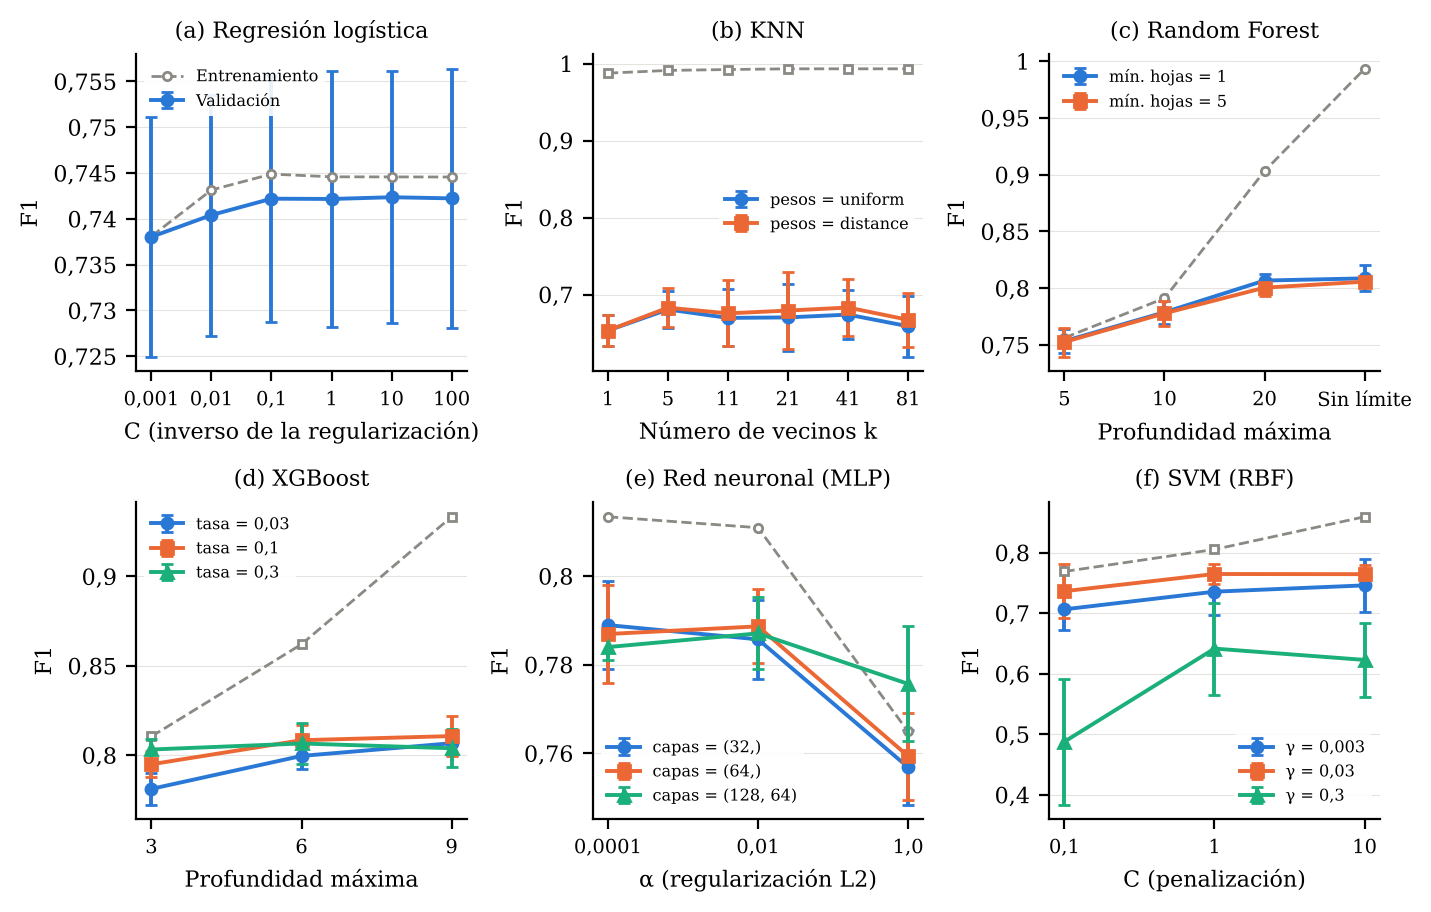

In [10]:
COLORES = ["#2a78d6", "#eb6834", "#1baf7a"]
MARCADORES = ["o", "s", "^"]
GRIS = "#8a8984"
paneles = {
    "Regresión logística": ("clf__C", None, "C (inverso de la regularización)"),
    "KNN": ("clf__n_neighbors", "clf__weights", "Número de vecinos k"),
    "Random Forest": ("clf__max_depth", "clf__min_samples_leaf", "Profundidad máxima"),
    "XGBoost": ("clf__max_depth", "clf__learning_rate", "Profundidad máxima"),
    "Red neuronal (MLP)": ("clf__alpha", "clf__hidden_layer_sizes", "α (regularización L2)"),
    "SVM (RBF)": ("clf__C", "clf__gamma", "C (penalización)"),
}
from matplotlib.ticker import FuncFormatter
coma = FuncFormatter(lambda v, _: f"{v:g}".replace(".", ","))
etiqueta = lambda v: "Sin límite" if v is None else str(v).replace(".", ",")
nombre_serie = {"clf__weights": "pesos", "clf__min_samples_leaf": "mín. hojas", "clf__learning_rate": "tasa",
                "clf__hidden_layer_sizes": "capas", "clf__gamma": "γ"}

fig, ejes = plt.subplots(2, 3, figsize=(7.2, 4.6))
for ax, (letra, (nombre, (px, ps, xlabel))) in zip(ejes.flat, zip("abcdef", paneles.items())):
    t = tablas[nombre].copy()
    valores_x = modelos[nombre]["malla"][px]
    pos_x = {etiqueta(v): i for i, v in enumerate(valores_x)}
    t["_x"] = t[px].map(lambda v: pos_x[etiqueta(v)])
    series = [None] if ps is None else modelos[nombre]["malla"][ps]
    mejor_serie = None if ps is None else t.iloc[0][ps]
    for k, s in enumerate(series):
        ts = t if ps is None else t[t[ps].map(etiqueta) == etiqueta(s)]
        ts = ts.sort_values("_x")
        lab = "Validación" if ps is None else f"{nombre_serie[ps]} = {etiqueta(s)}"
        ax.errorbar(ts["_x"], ts["f1_val"], yerr=ts["f1_val_ic"], color=COLORES[k], marker=MARCADORES[k],
                    ms=4, lw=1.4, capsize=2, label=lab)
        if (ps is None) or (etiqueta(s) == etiqueta(mejor_serie)):
            ax.plot(ts["_x"], ts["f1_ent"], color=GRIS, ls="--", lw=1, marker=MARCADORES[k], ms=3,
                    mfc="white", label="Entrenamiento" if ps is None else "_nolegend_")
    ax.set_xticks(range(len(valores_x)), [etiqueta(v) for v in valores_x], fontsize=7)
    ax.set_xlabel(xlabel); ax.set_ylabel("F1")
    ax.set_title(f"({letra}) {nombre}", fontsize=8)
    ax.grid(axis="y", lw=0.4, color="#e4e3df")
    ax.yaxis.set_major_formatter(coma)
    ax.legend(fontsize=5.8, frameon=True, framealpha=0.9, edgecolor="none", loc="best")
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / "fig2_hiperparametros.png", dpi=300)
plt.show()

### 3.4 Comparación de los modelos (Tabla IV del informe)
Para cada modelo se toma la mejor combinación de hiperparámetros. Entrenamiento y validación: media ± IC95 % de los
5 pliegues. Prueba: el modelo se reentrena con todos sus datos de ajuste y se evalúa una sola vez en el conjunto de prueba.

In [11]:
filas, prueba = [], {}
for nombre, busqueda in busquedas.items():
    mejor = tablas[nombre].iloc[0]
    prueba[nombre] = ev.metricas_prueba(busqueda.best_estimator_, X_pru, y_pru)
    fila = {"Modelo": nombre,
            "Mejores hiperparámetros": ", ".join(f"{k.replace('clf__', '')}={etiqueta(v)}" for k, v in busqueda.best_params_.items())}
    for m in ev.METRICAS:
        fila[f"{m}_ent"] = mejor[f"{m}_ent"]; fila[f"{m}_ent_ic"] = mejor[f"{m}_ent_ic"]
        fila[f"{m}_val"] = mejor[f"{m}_val"]; fila[f"{m}_val_ic"] = mejor[f"{m}_val_ic"]
        fila[f"{m}_pru"] = prueba[nombre][m]
    filas.append(fila)
resumen = pd.DataFrame(filas).sort_values("f1_val", ascending=False).reset_index(drop=True)
resumen.to_csv(RUTA_RESULTADOS / "resumen_modelos.csv", index=False)

vista = resumen[["Modelo", "Mejores hiperparámetros"]].copy()
for m in ["f1", "roc_auc"]:
    n = ev.NOMBRES_METRICAS[m]
    vista[f"{n} entren."] = [ev.fmt(a, b) for a, b in zip(resumen[f"{m}_ent"], resumen[f"{m}_ent_ic"])]
    vista[f"{n} valid."] = [ev.fmt(a, b) for a, b in zip(resumen[f"{m}_val"], resumen[f"{m}_val_ic"])]
    vista[f"{n} prueba"] = [ev.fmt(a) for a in resumen[f"{m}_pru"]]
vista

,Modelo,Mejores hiperparámetros,F1 entren.,F1 valid.,F1 prueba,AUC-ROC entren.,AUC-ROC valid.,AUC-ROC prueba
0,XGBoost,"learning_rate=0,1, max_depth=9","0,933 ± 0,001","0,811 ± 0,011","0,820","0,992 ± 0,000","0,938 ± 0,004","0,943"
1,Random Forest,"max_depth=Sin límite, min_samples_leaf=1","0,993 ± 0,001","0,809 ± 0,012","0,818","1,000 ± 0,000","0,936 ± 0,003","0,941"
2,Red neuronal (MLP),"alpha=0,0001, hidden_layer_sizes=(32,)","0,813 ± 0,006","0,789 ± 0,010","0,793","0,941 ± 0,002","0,927 ± 0,003","0,928"
3,SVM (RBF),"C=1, gamma=0,03","0,805 ± 0,001","0,765 ± 0,017","0,768","0,927 ± 0,001","0,897 ± 0,010","0,903"
4,Regresión logística,C=10,"0,745 ± 0,003","0,742 ± 0,014","0,746","0,891 ± 0,002","0,889 ± 0,007","0,890"
5,KNN,"n_neighbors=41, weights=distance","0,993 ± 0,001","0,683 ± 0,037","0,699","1,000 ± 0,000","0,852 ± 0,022","0,865"


In [12]:
# Sensibilidad, precisión y exactitud en validación y prueba
vista2 = resumen[["Modelo"]].copy()
for m in ["recall", "precision", "accuracy"]:
    n = ev.NOMBRES_METRICAS[m]
    vista2[f"{n} valid."] = [ev.fmt(a, b) for a, b in zip(resumen[f"{m}_val"], resumen[f"{m}_val_ic"])]
    vista2[f"{n} prueba"] = [ev.fmt(a) for a in resumen[f"{m}_pru"]]
vista2

,Modelo,Sensibilidad valid.,Sensibilidad prueba,Precisión valid.,Precisión prueba,Exactitud valid.,Exactitud prueba
0,XGBoost,"0,827 ± 0,015","0,836","0,795 ± 0,012","0,805","0,857 ± 0,008","0,864"
1,Random Forest,"0,795 ± 0,013","0,807","0,822 ± 0,012","0,829","0,860 ± 0,008","0,867"
2,Red neuronal (MLP),"0,764 ± 0,018","0,772","0,816 ± 0,010","0,816","0,848 ± 0,006","0,851"
3,SVM (RBF),"0,782 ± 0,020","0,777","0,749 ± 0,025","0,760","0,822 ± 0,014","0,826"
4,Regresión logística,"0,766 ± 0,015","0,767","0,720 ± 0,014","0,726","0,803 ± 0,011","0,806"
5,KNN,"0,601 ± 0,047","0,628","0,791 ± 0,027","0,789","0,793 ± 0,019","0,800"


### 3.5 Curvas ROC en el conjunto de prueba (Fig. 3 del informe)

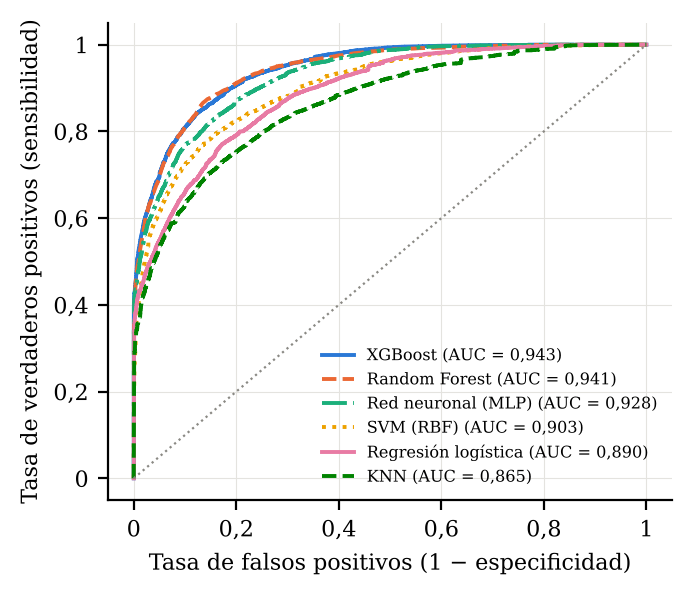

In [13]:
COLORES6 = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
ESTILOS = ["-", "--", "-.", ":", "-", "--"]
fig, ax = plt.subplots(figsize=(3.5, 3.0))
for k, nombre in enumerate(resumen["Modelo"]):
    fpr, tpr, _ = roc_curve(y_pru, ev.puntajes(busquedas[nombre].best_estimator_, X_pru))
    ax.plot(fpr, tpr, color=COLORES6[k], ls=ESTILOS[k], lw=1.4,
            label=f"{nombre} (AUC = {ev.fmt(prueba[nombre]['roc_auc'])})")
ax.plot([0, 1], [0, 1], color=GRIS, lw=0.8, ls=":")
ax.set_xlabel("Tasa de falsos positivos (1 − especificidad)")
ax.set_ylabel("Tasa de verdaderos positivos (sensibilidad)")
ax.legend(fontsize=5.8, frameon=False, loc="lower right")
ax.grid(lw=0.4, color="#e4e3df")
ax.xaxis.set_major_formatter(coma); ax.yaxis.set_major_formatter(coma)
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / "fig3_roc_prueba.png", dpi=300)
plt.show()

### 3.6 Matriz de confusión del mejor modelo en prueba

In [14]:
mejor_modelo = resumen.loc[0, "Modelo"]
mc = confusion_matrix(y_pru, busquedas[mejor_modelo].best_estimator_.predict(X_pru))
print("Mejor modelo según F1 de validación:", mejor_modelo)
pd.DataFrame(mc, index=["Real: no cancelada", "Real: cancelada"],
             columns=["Predicha: no cancelada", "Predicha: cancelada"])

Mejor modelo según F1 de validación: XGBoost


,Predicha: no cancelada,Predicha: cancelada
Real: no cancelada,13206,1795
Real: cancelada,1446,7393


### 3.7 Efecto de la variable `country`
En la Sección II se dejó pendiente evaluar `country`, señalada en otros trabajos como posible fuga de información.
Se repite la validación cruzada de los dos mejores modelos, con sus mejores hiperparámetros, sin esta variable.

In [15]:
top2 = list(resumen["Modelo"].head(2))
filas_pais = []
for nombre in top2:
    m = modelos[nombre]
    Xm, ym, gm = (X_ent.iloc[idx_muestra], y_ent[idx_muestra], g_ent[idx_muestra]) if m["muestra"] else (X_ent, y_ent, g_ent)
    for incluir in [True, False]:
        cols = pp.columnas_entrada(incluir_pais=incluir)
        pipe = Pipeline([("prep", pp.construir_preprocesador(incluir_pais=incluir)), ("clf", clone(m["estimador"]))])
        pipe.set_params(**busquedas[nombre].best_params_)
        cv = cross_validate(pipe, Xm[cols], ym, groups=gm, cv=ev.validacion_cruzada(), scoring=ev.METRICAS, n_jobs=m["n_jobs"])
        f1m, f1ic = ev.intervalo_confianza(cv["test_f1"]); aucm, aucic = ev.intervalo_confianza(cv["test_roc_auc"])
        filas_pais.append({"Modelo": nombre, "country": "con" if incluir else "sin",
                           "F1 valid.": ev.fmt(f1m, f1ic), "AUC-ROC valid.": ev.fmt(aucm, aucic),
                           "f1": f1m, "auc": aucm})
pais = pd.DataFrame(filas_pais)
pais.to_csv(RUTA_RESULTADOS / "efecto_country.csv", index=False)
pais[["Modelo", "country", "F1 valid.", "AUC-ROC valid."]]

,Modelo,country,F1 valid.,AUC-ROC valid.
0,XGBoost,con,"0,811 ± 0,011","0,938 ± 0,004"
1,XGBoost,sin,"0,756 ± 0,012","0,893 ± 0,004"
2,Random Forest,con,"0,809 ± 0,012","0,936 ± 0,003"
3,Random Forest,sin,"0,751 ± 0,006","0,887 ± 0,002"


### 3.8 Modelos que pasan a la Sección V

In [16]:
seleccion = {nombre: {"parametros": {k: (list(v) if isinstance(v, tuple) else v) for k, v in busquedas[nombre].best_params_.items()},
                      "muestra": modelos[nombre]["muestra"]} for nombre in top2}
with open(RUTA_RESULTADOS / "mejores_modelos.json", "w", encoding="utf-8") as f:
    json.dump(seleccion, f, ensure_ascii=False, indent=2)
print("Dos mejores modelos (F1 de validación):", top2)
seleccion

Dos mejores modelos (F1 de validación): ['XGBoost', 'Random Forest']


{'XGBoost': {'parametros': {'clf__learning_rate': 0.1, 'clf__max_depth': 9},
  'muestra': False},
 'Random Forest': {'parametros': {'clf__max_depth': None,
   'clf__min_samples_leaf': 1},
  'muestra': False}}